# 05: Live Language Model Explorer

## Objective

Interactively investigate unigram probability
estimation using a pretrained language model.

In [1]:
import gc
import math
import time
import json

from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, clear_output

from replica.feature.frequency.sampled import (
    SampledUnigramSource,
    mc_estimate,
)

PROJECT_ROOT = (
    Path.home()
    / "PROJECTS"
    / "unigram-surprisal-demo"
)

RESULTS_DIR = PROJECT_ROOT / "results"

MODEL_NAME = "distilgpt2"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

NMC_COLOR = "#E69F00"
MMC_COLOR = "#009E73"

print("Model:", MODEL_NAME)
print("Device:", DEVICE)

Model: distilgpt2
Device: cuda


## Experiment Execution

The experiment exposes the following parameters:

- Target vocabulary
- Number of generated sequences
- Maximum sequence length
- Random seed

Probability estimates are converted to surprisal
using the negative base-2 logarithm and zero probabilities correspond to infinite surprisal.

In [2]:
def to_surprisal(probability):
    return (
        -math.log2(probability)
        if probability > 0
        else math.inf
    )


def run_language_model_experiment(
    words,
    n_samples=16,
    max_len=20,
    seed=42,
):
    words = list(dict.fromkeys(
        word.strip()
        for word in words
        if word.strip()
    ))

    if not words:
        raise ValueError("Provide at least one target word.")

    if any(len(word.split()) != 1 for word in words):
        raise ValueError("Use individual words, not phrases.")

    start = time.perf_counter()

    source = None

    try:
        source = SampledUnigramSource(
            model_name=MODEL_NAME,
            n_samples=n_samples,
            max_len=max_len,
            device=DEVICE,
            seed=seed,
            batch_size=4,
            gen_batch_size=4,
        )

        # Original REPLICA MMC estimator
        mmc = source.estimate_words([
            " " + word for word in words
        ])

        # Shared generated samples
        samples = list(source._samples)

        rows = []

        for word in words:
            # Original REPLICA NMC estimator
            p_nmc = mc_estimate(word, samples)
            p_mmc = mmc[" " + word]

            rows.append({
                "word": word,
                "nmc_probability": p_nmc,
                "mmc_probability": p_mmc,
                "nmc_surprisal": to_surprisal(p_nmc),
                "mmc_surprisal": to_surprisal(p_mmc),
            })

        results = pd.DataFrame(rows)

        elapsed = time.perf_counter() - start

        return {
            "results": results,
            "samples": samples,
            "model": MODEL_NAME,
            "device": DEVICE,
            "n_samples": n_samples,
            "max_len": max_len,
            "seed": seed,
            "execution_time": elapsed,
        }

    finally:
        del source

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

In [3]:
result = run_language_model_experiment(
    words=["the", "dog", "cat", "coriander"],
    n_samples=16,
    max_len=20,
    seed=42,
)

display(
    result["results"].style.format({
        "nmc_probability": "{:.8e}",
        "mmc_probability": "{:.8e}",
        "nmc_surprisal": "{:.4f}",
        "mmc_surprisal": "{:.4f}",
    })
)

print(
    f"Execution time: "
    f"{result['execution_time']:.3f} s"
)

print("Generated samples:", len(result["samples"]))

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


,word,nmc_probability,mmc_probability,nmc_surprisal,mmc_surprisal
0,the,2.80000000e-02,2.97862425e-02,5.1584,5.0692
1,dog,0.00000000e+00,8.89982906e-05,inf,13.4559
2,cat,0.00000000e+00,6.74623245e-05,inf,13.8556
3,coriander,0.00000000e+00,1.33763791e-07,inf,22.8338


Execution time: 5.671 s
Generated samples: 16


In [5]:
def visualize_language_model_experiment(result):

    results = result["results"]

    display(
        results.style.format({
            "nmc_probability": "{:.6e}",
            "mmc_probability": "{:.6e}",
            "nmc_surprisal": "{:.4f}",
            "mmc_surprisal": "{:.4f}",
        })
    )

    print(f"Model: {result['model']}")
    print(f"Device: {result['device']}")
    print(f"Generated sequences: {len(result['samples'])}")
    print(f"Execution time: {result['execution_time']:.3f} s")

    coverage = pd.Series({
        "NMC": (results["nmc_probability"] > 0).mean(),
        "MMC": (results["mmc_probability"] > 0).mean(),
    })

    fig, ax = plt.subplots(figsize=(7, 4))

    bars = ax.bar(
        coverage.index,
        coverage.values,
        color=[NMC_COLOR, MMC_COLOR],
        width=0.5,
    )

    ax.bar_label(
        bars,
        labels=[f"{v:.1%}" for v in coverage],
        padding=4,
    )

    ax.set_title("Target Vocabulary Coverage")
    ax.set_ylabel("Proportion of target words")
    ax.set_ylim(0, 1.15)
    ax.grid(axis="y", alpha=0.2)

    fig.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(10, 5))

    for method, color, marker in [
        ("nmc", NMC_COLOR, "o"),
        ("mmc", MMC_COLOR, "x"),
    ]:
        column = f"{method}_probability"
        valid = results[column] > 0

        ax.scatter(
            np.flatnonzero(valid.to_numpy()),
            results.loc[valid, column],
            label=method.upper(),
            color=color,
            marker=marker,
            s=100,
        )

    ax.set_xticks(
        range(len(results)),
        results["word"],
    )

    ax.set_yscale("log")
    ax.set_ylabel("Estimated probability")
    ax.set_title("Unigram Probability Estimates")
    ax.legend()
    ax.grid(alpha=0.2, which="both")

    fig.tight_layout()
    plt.show()

    print("Zero probabilities are omitted from the log plot.")

    print("\nGenerated sample preview:")

    display(pd.DataFrame({
        "sample_id": range(1, len(result["samples"]) + 1),
        "text": result["samples"],
    }).head(10))

,word,nmc_probability,mmc_probability,nmc_surprisal,mmc_surprisal
0,the,2.800000e-02,2.978624e-02,5.1584,5.0692
1,dog,0.000000e+00,8.899829e-05,inf,13.4559
2,cat,0.000000e+00,6.746232e-05,inf,13.8556
3,coriander,0.000000e+00,1.337638e-07,inf,22.8338


Model: distilgpt2
Device: cuda
Generated sequences: 16
Execution time: 5.671 s


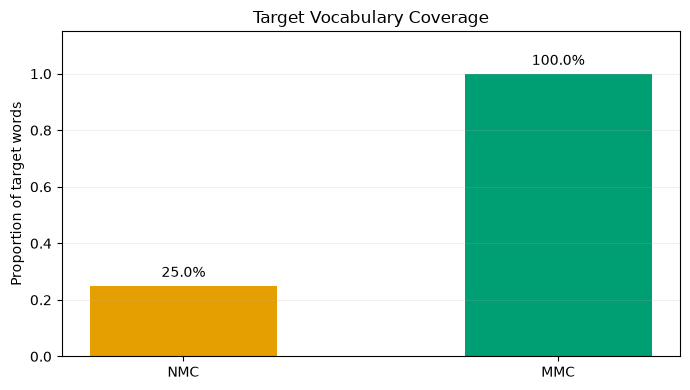

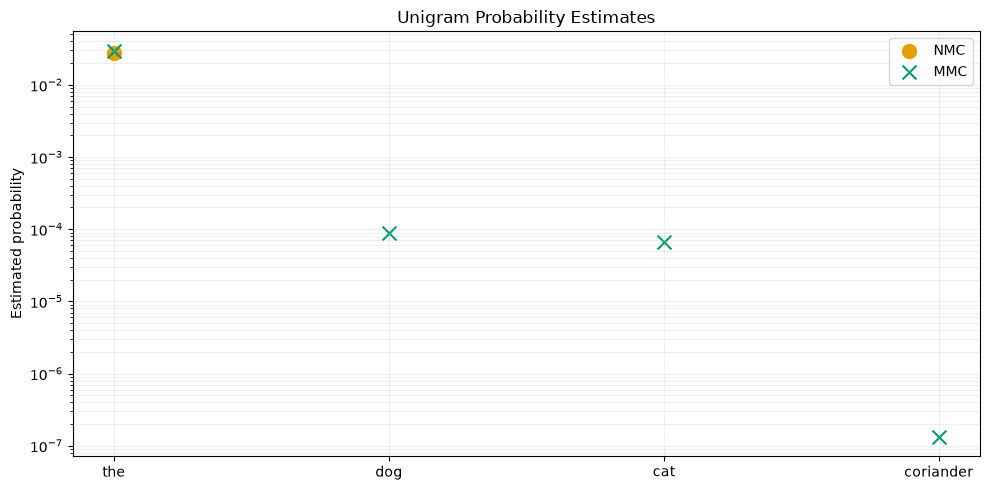

Zero probabilities are omitted from the log plot.

Generated sample preview:


,sample_id,text
0,1,"for several years, and it began spreading and..."
1,2,All images published under the Creative Common...
2,3,III.III.\n\n\n\nPhysical evidence of a male su...
3,4,As Edward Snowden and James Comey continue to...
4,5,"Still, high-resolution dissecting video offers..."
5,6,Caroline all wore the best draft pick no matte...
6,7,Teres Wirbe 4X Wirbe 0X Watercolour Wirbe 4X Aqua
7,8,Email: mrottresselpore@jezebel.com; Twitter::
8,9,"DEFAULT USE > --password = -ok == -rm -r ""Debu..."
9,10,Extending the family to a village is easy. If ...


In [6]:
visualize_language_model_experiment(result)

## Interactive Language Model Explorer

In [7]:
words_widget = widgets.Textarea(
    value="the, dog, cat, coriander",
    description="Target words:",
    style={"description_width": "initial"},
    layout=widgets.Layout(
        width="85%",
        height="80px",
    ),
)

samples_widget = widgets.IntSlider(
    value=16,
    min=16,
    max=256,
    step=16,
    description="Samples:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="85%"),
)

length_widget = widgets.IntSlider(
    value=20,
    min=10,
    max=50,
    step=10,
    description="Max tokens:",
    continuous_update=False,
    style={"description_width": "initial"},
    layout=widgets.Layout(width="85%"),
)

seed_widget = widgets.BoundedIntText(
    value=42,
    min=0,
    max=999999,
    description="Seed:",
)

run_button = widgets.Button(
    description="Run estimation",
    button_style="primary",
    icon="play",
)

status_widget = widgets.Label(
    value="Ready."
)

output = widgets.Output()

experiment_history = []

In [8]:
def on_run_clicked(button):

    button.disabled = True

    status_widget.value = "Running estimation..."

    with output:
        clear_output(wait=True)

        try:
            words = words_widget.value.split(",")

            result = run_language_model_experiment(
                words=words,
                n_samples=samples_widget.value,
                max_len=length_widget.value,
                seed=seed_widget.value,
            )

            experiment_history.append(result)

            visualize_language_model_experiment(result)

            status_widget.value = "Experiment completed."

        except Exception:
            import traceback

            traceback.print_exc()

            status_widget.value = "Experiment failed."

        finally:
            button.disabled = False


run_button.on_click(on_run_clicked)

display(widgets.VBox([
    widgets.HTML(
        "<h2>Live Language Model Explorer</h2>"
    ),
    widgets.Label(
        value=f"Model: {MODEL_NAME} | Device: {DEVICE}"
    ),
    words_widget,
    samples_widget,
    length_widget,
    seed_widget,
    run_button,
    status_widget,
    output,
]))